In [1]:
from scipy.interpolate import CubicSpline
from scipy.signal import correlate
import matplotlib.pyplot as plt
import pandas as pd
import numpy  as np
import json, os, math
pd.set_option('display.max_columns', None)

In [2]:
TEST    = json.loads(open('../info.json', 'r').read()).get('test', 1)
FOLDER  = f'test{TEST}'
SOURCE  = f'{FOLDER}/files/data.csv'
RESULTS = f'{FOLDER}/results'
AXES    = json.loads(open(f'{FOLDER}/info.json', 'r').read()).get('axes', {}) if os.path.exists(f'{FOLDER}/info.json') else {}

print('SOURCE:', SOURCE)
AXES

SOURCE: test1/files/data.csv


{'ay': 'az',
 'az': 'ay',
 'wy': 'wz',
 'wz': '-wy',
 'pitch': 'roll',
 'roll': '-pitch'}

# IMPORTANDO DADOS
- Saída do `Monitor`: cada amostra traz o MRU em teste (`target_`), gravado em `SCALE_MODE` (m/s², graus/s, graus, °C), e a referência (`ref_`) no instante mais próximo

In [3]:
df = pd.read_csv(SOURCE)
print(len(df), 'linhas')
df.head()

1801 linhas


,time,target_wz,target_tmp,target_pitch,target_e,target_ay,target_ax,target_wx,target_wy,target_az,target_roll,target_yaw,static,ref_sample_time,ref_wz,ref_pitch,ref_q0,ref_q1,ref_ay,ref_wx,ref_ax,ref_q2,ref_wy,ref_la_pos_mon_d,ref_az,ref_roll,ref_yaw,ref_q3
0,0.0,-6.92455,53.0,-1.525,-22.176,10.733555,0.194623,-47.92960,-1.16726,-0.614769,18.043,2.936,False,605000000.0,0.200478,0.304871,-0.8118,0.5835,9.59,-44.581846,0.06400,0.01196,0.471315,-0.5252,0.8262,-71.390541,2.771970,-0.02120
1,0.1,-8.13221,52.9,-0.742,-16.704,11.618576,0.294719,-58.13591,-1.05996,-0.532550,12.732,2.725,False,705000000.0,0.165413,0.337243,-0.7843,0.6199,10.54,-54.981030,0.09128,0.01243,0.546086,-0.4685,0.8149,-76.661753,2.723841,-0.02047
2,0.2,-8.42212,53.1,0.119,-10.440,12.899422,0.256924,-67.53252,-1.95110,-2.312996,6.586,2.578,False,805000000.0,0.189592,0.366750,-0.7505,0.6604,11.46,-62.337808,0.12330,0.01297,0.585563,-0.4231,0.7793,-82.677810,2.667691,-0.01959
3,0.3,-9.92099,53.3,1.010,-3.240,12.406766,0.425020,-67.39252,-1.05936,-0.455019,-0.016,2.655,False,905000000.0,0.310085,0.387721,-0.7116,0.7021,12.17,-66.291217,0.19090,0.01440,-1.635795,-0.3990,0.7029,-89.209529,2.743322,-0.01942
4,0.4,-9.44709,52.9,1.984,3.744,12.362390,0.271203,-66.62502,-1.97845,-0.208931,-6.779,2.656,False,5000000.0,0.653172,0.442381,-0.6696,0.7424,12.51,-66.806879,0.17590,0.01442,0.789536,-0.4016,0.5932,-95.913135,2.624720,-0.01821


# EIXOS DO KERNEL
- O firmware recebe o Kernel nos eixos do próprio sensor (ICD: X lateral, Y longitudinal, Z para cima), e é nesses eixos que toda etapa precisa ajustar o que exporta
- O `info.json` do teste diz de onde sai cada eixo quando o arquivo passou por outro formato antes; `-` inverte o sinal. A gravação do Monitor já vem nos eixos do Kernel e dispensa o arquivo

In [4]:
SENSORS = ['ax', 'ay', 'az', 'wx', 'wy', 'wz']
ANGLES  = ['pitch', 'roll', 'yaw']


def getAxis(df, var):
    source = AXES.get(var, var)
    return -df[f'target_{source[1:]}'] if source.startswith('-') else df[f'target_{source}']


target    = {var: getAxis(df, var) for var in SENSORS + ANGLES}
reference = {f'ref_{var}': df[f'ref_{var}'] for var in ANGLES}

df = pd.DataFrame({'time': df.time, 'static': df.static, 'tmp': df.target_tmp, **target, **reference})
df

,time,static,tmp,ax,ay,az,wx,wy,wz,pitch,roll,yaw,ref_pitch,ref_roll,ref_yaw
0,0.0,False,53.0,0.194623,-0.614769,10.733555,-47.92960,-6.92455,1.16726,18.043,1.525,2.936,0.304871,-71.390541,2.771970
1,0.1,False,52.9,0.294719,-0.532550,11.618576,-58.13591,-8.13221,1.05996,12.732,0.742,2.725,0.337243,-76.661753,2.723841
2,0.2,False,53.1,0.256924,-2.312996,12.899422,-67.53252,-8.42212,1.95110,6.586,-0.119,2.578,0.366750,-82.677810,2.667691
3,0.3,False,53.3,0.425020,-0.455019,12.406766,-67.39252,-9.92099,1.05936,-0.016,-1.010,2.655,0.387721,-89.209529,2.743322
4,0.4,False,52.9,0.271203,-0.208931,12.362390,-66.62502,-9.44709,1.97845,-6.779,-1.984,2.656,0.442381,-95.913135,2.624720
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1796,279.5,True,55.6,0.235938,-0.402014,9.717615,-0.09929,-0.00493,0.03678,-2.509,-1.368,5.289,1.645535,-92.131613,6.371291
1797,279.6,True,55.4,0.257170,-0.404622,9.768983,-0.18597,0.50338,-0.40111,-2.506,-1.367,5.291,1.644962,-92.131613,6.371291
1798,279.7,True,55.6,0.266545,-0.485586,9.796167,0.06592,0.14588,0.14609,-2.506,-1.367,5.289,1.645535,-92.131613,6.377020
1799,279.8,True,55.5,0.222170,-0.409330,9.755871,-0.01801,0.04660,0.00522,-2.504,-1.367,5.290,1.644962,-92.131613,6.377020


# PERÍODO DE AMOSTRAGEM
- Grade regular de $\Delta t$ com a leitura mais próxima de cada ponto, a até meio período dele; no buraco da gravação a grade fica vazia e a linha sai, em vez de repetir a última amostra

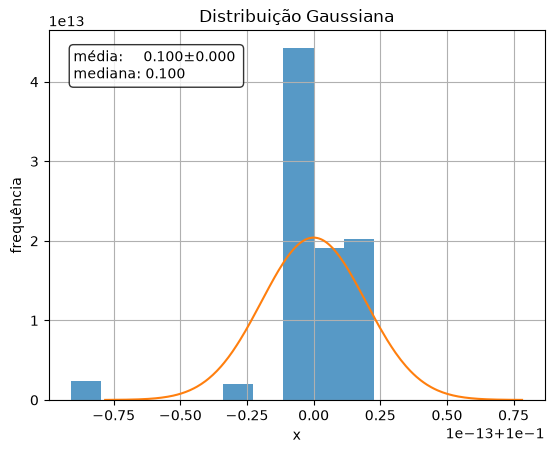

1800 amostras na grade de 0.1 s | buraco de 100 s


,time,static,tmp,ax,ay,az,wx,wy,wz,pitch,roll,yaw,ref_pitch,ref_roll,ref_yaw
0,0.0,False,53.0,0.194623,-0.614769,10.733555,-47.92960,-6.92455,1.16726,18.043,1.525,2.936,0.304871,-71.390541,2.771970
1,0.1,False,52.9,0.294719,-0.532550,11.618576,-58.13591,-8.13221,1.05996,12.732,0.742,2.725,0.337243,-76.661753,2.723841
2,0.2,False,53.1,0.256924,-2.312996,12.899422,-67.53252,-8.42212,1.95110,6.586,-0.119,2.578,0.366750,-82.677810,2.667691
3,0.3,False,53.3,0.425020,-0.455019,12.406766,-67.39252,-9.92099,1.05936,-0.016,-1.010,2.655,0.387721,-89.209529,2.743322
4,0.4,False,52.9,0.271203,-0.208931,12.362390,-66.62502,-9.44709,1.97845,-6.779,-1.984,2.656,0.442381,-95.913135,2.624720
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1795,279.4,True,55.5,0.269369,-0.416959,9.760873,-0.09321,-0.21920,-0.25104,-2.510,-1.368,5.289,1.644962,-92.131613,6.371291
1796,279.5,True,55.6,0.235938,-0.402014,9.717615,-0.09929,-0.00493,0.03678,-2.509,-1.368,5.289,1.645535,-92.131613,6.371291
1797,279.6,True,55.4,0.257170,-0.404622,9.768983,-0.18597,0.50338,-0.40111,-2.506,-1.367,5.291,1.644962,-92.131613,6.371291
1798,279.7,True,55.6,0.266545,-0.485586,9.796167,0.06592,0.14588,0.14609,-2.506,-1.367,5.289,1.645535,-92.131613,6.377020


In [5]:
def gaussian(data):
    data  = np.array(data)
    n     = data.shape[0]
    mu    = data.mean()
    sigma = data.std()

    x  = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
    y  = (1/(sigma*np.sqrt(2*np.pi))) * np.exp(-0.5*((x - mu)/sigma)**2)
    plt.title(f'Distribuição Gaussiana')
    plt.hist(data, density=True, alpha=0.75)
    plt.plot(x, y)

    text = f'média:     {mu:.3f}±{sigma:.3f} \nmediana: {np.median(data):.3f}'
    opts = dict(boxstyle='round', facecolor='white', alpha=0.8)
    plt.text(0.05, 0.95, text, transform=plt.gca().transAxes, verticalalignment='top', bbox=opts)
    plt.xlabel('x'); plt.ylabel('frequência'); plt.grid()

# GRADE E LEITURAS ARREDONDADAS NA MESMA CASA: SEM ISSO O RUÍDO DE FLOAT (1e-14) FAZ O merge_asof SEGURAR A AMOSTRA ANTERIOR
def normalizePeriod(df, key, dt=0.15):
    df = df.copy().sort_values(key)
    df[key] = (df[key] - df[key].iloc[0]).round(10)

    n = int(np.floor(df[key].iloc[-1] / dt)) + 1
    newAxis = np.round(np.linspace(0, dt*(n-1), n), 10)
    target  = pd.DataFrame({key: newAxis})
    return pd.merge_asof(target, df, on=key, direction='nearest', tolerance=dt/2).dropna().reset_index(drop=True)


time = df.time.diff()[1:].to_numpy()
dt   = round(float(np.median(time)), 4)

gaussian(time[time < 3*dt]); plt.show()
df = normalizePeriod(df, 'time', dt).astype({'static': bool})
print(len(df), 'amostras na grade de', dt, 's | buraco de', round(df.time.diff().max()), 's')
df

# TAXA DE REFERÊNCIA
- A referência entrega atitude, não giroscópio. A taxa do corpo sai da derivada dos ângulos de Euler xyz da referência, $R = R_z(\psi)\,R_y(\theta)\,R_x(\phi)$, por spline cúbica em cada trecho contínuo:

$$\omega = \begin{bmatrix} \dot\phi - \dot\psi\sin\theta \\ \dot\theta\cos\phi + \dot\psi\sin\phi\cos\theta \\ -\dot\theta\sin\phi + \dot\psi\cos\phi\cos\theta \end{bmatrix}$$

- A diferença finita centrada a 10 Hz achataria o pico do balanço em $(\omega\Delta t)^2/6$, ~1,6% no pêndulo, e esse erro iria inteiro para o fator de escala do giroscópio

In [6]:
# TAXA DO CORPO PELA DERIVADA DOS ÂNGULOS DE EULER xyz, SEM ATRAVESSAR O BURACO ENTRE TRECHOS
def getRates(df):
    segment = (df.time.diff() > 1.5*dt).cumsum()
    rates   = []

    for _, part in df.groupby(segment):
        angles             = np.unwrap(np.radians(part[['ref_roll', 'ref_pitch', 'ref_yaw']].to_numpy()), axis=0)
        phi, theta, _      = angles.T
        dphi, dtheta, dpsi = CubicSpline(part.time, angles)(part.time, 1).T
        rates.append(np.c_[dphi - dpsi*np.sin(theta), dtheta*np.cos(phi) + dpsi*np.sin(phi)*np.cos(theta), -dtheta*np.sin(phi) + dpsi*np.cos(phi)*np.cos(theta)])

    return np.degrees(np.vstack(rates))


df[['ref_wx', 'ref_wy', 'ref_wz']] = getRates(df)
df[['wx', 'wy', 'wz', 'ref_wx', 'ref_wy', 'ref_wz']].describe()

,wx,wy,wz,ref_wx,ref_wy,ref_wz
count,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000
mean,-0.110539,-0.007866,-0.010999,-0.102769,-0.011156,-0.000662
std,18.323658,2.617892,0.443921,18.408526,0.205396,0.214293
min,-67.532520,-9.920990,-3.193530,-67.172037,-0.903494,-1.060230
25%,-0.347303,-0.378135,-0.218927,-0.343377,-0.036597,-0.007917
50%,-0.000365,0.006265,-0.010835,-0.000341,-0.012268,0.000124
75%,0.362387,0.398352,0.193785,0.361192,0.009684,0.007463
max,66.068610,11.926620,1.978450,66.774320,1.487548,0.815388


# DEFASAGEM
- Atraso do MRU contra a referência: pico da correlação cruzada do módulo da taxa angular, que não depende dos eixos, só no trecho em movimento (`static` falso)
- Todas as colunas do MRU andam juntas, sem atravessar o buraco da gravação; as amostras que ficam sem par saem

In [7]:
# ATRASO DO MRU CONTRA A REFERÊNCIA PELO PICO DA CORRELAÇÃO CRUZADA
class Phaser:
    def __init__(self, columns):
        self.columns = columns

    def get(self, df, target, reference):
        if df.empty:
            return 0

        x = np.linalg.norm(df[target], axis=1)
        y = np.linalg.norm(df[reference], axis=1)

        correlation = correlate(y - y.mean(), x - x.mean(), mode='full')    # PELA FFT: A DIRETA É N² E A 200 Hz NÃO TERMINA
        lags = np.arange(-len(df) + 1, len(df))
        return lags[np.argmax(correlation)]

    def set(self, df, lag):
        block = (df.time.diff() > 1.5*dt).cumsum()    # O DESLOCAMENTO NÃO ATRAVESSA O BURACO DA GRAVAÇÃO

        df[self.columns] = df.groupby(block)[self.columns].shift(lag)
        return df.dropna(subset=self.columns).reset_index(drop=True)


phaser = Phaser(['tmp'] + SENSORS + ANGLES)
lag    = phaser.get(df[~df.static], ['wx', 'wy', 'wz'], ['ref_wx', 'ref_wy', 'ref_wz'])
df     = phaser.set(df, lag)
print('defasagem:', lag, 'amostras |', len(df), 'linhas')

defasagem: 0 amostras | 1800 linhas


# VISUALIZAÇÃO DOS DADOS

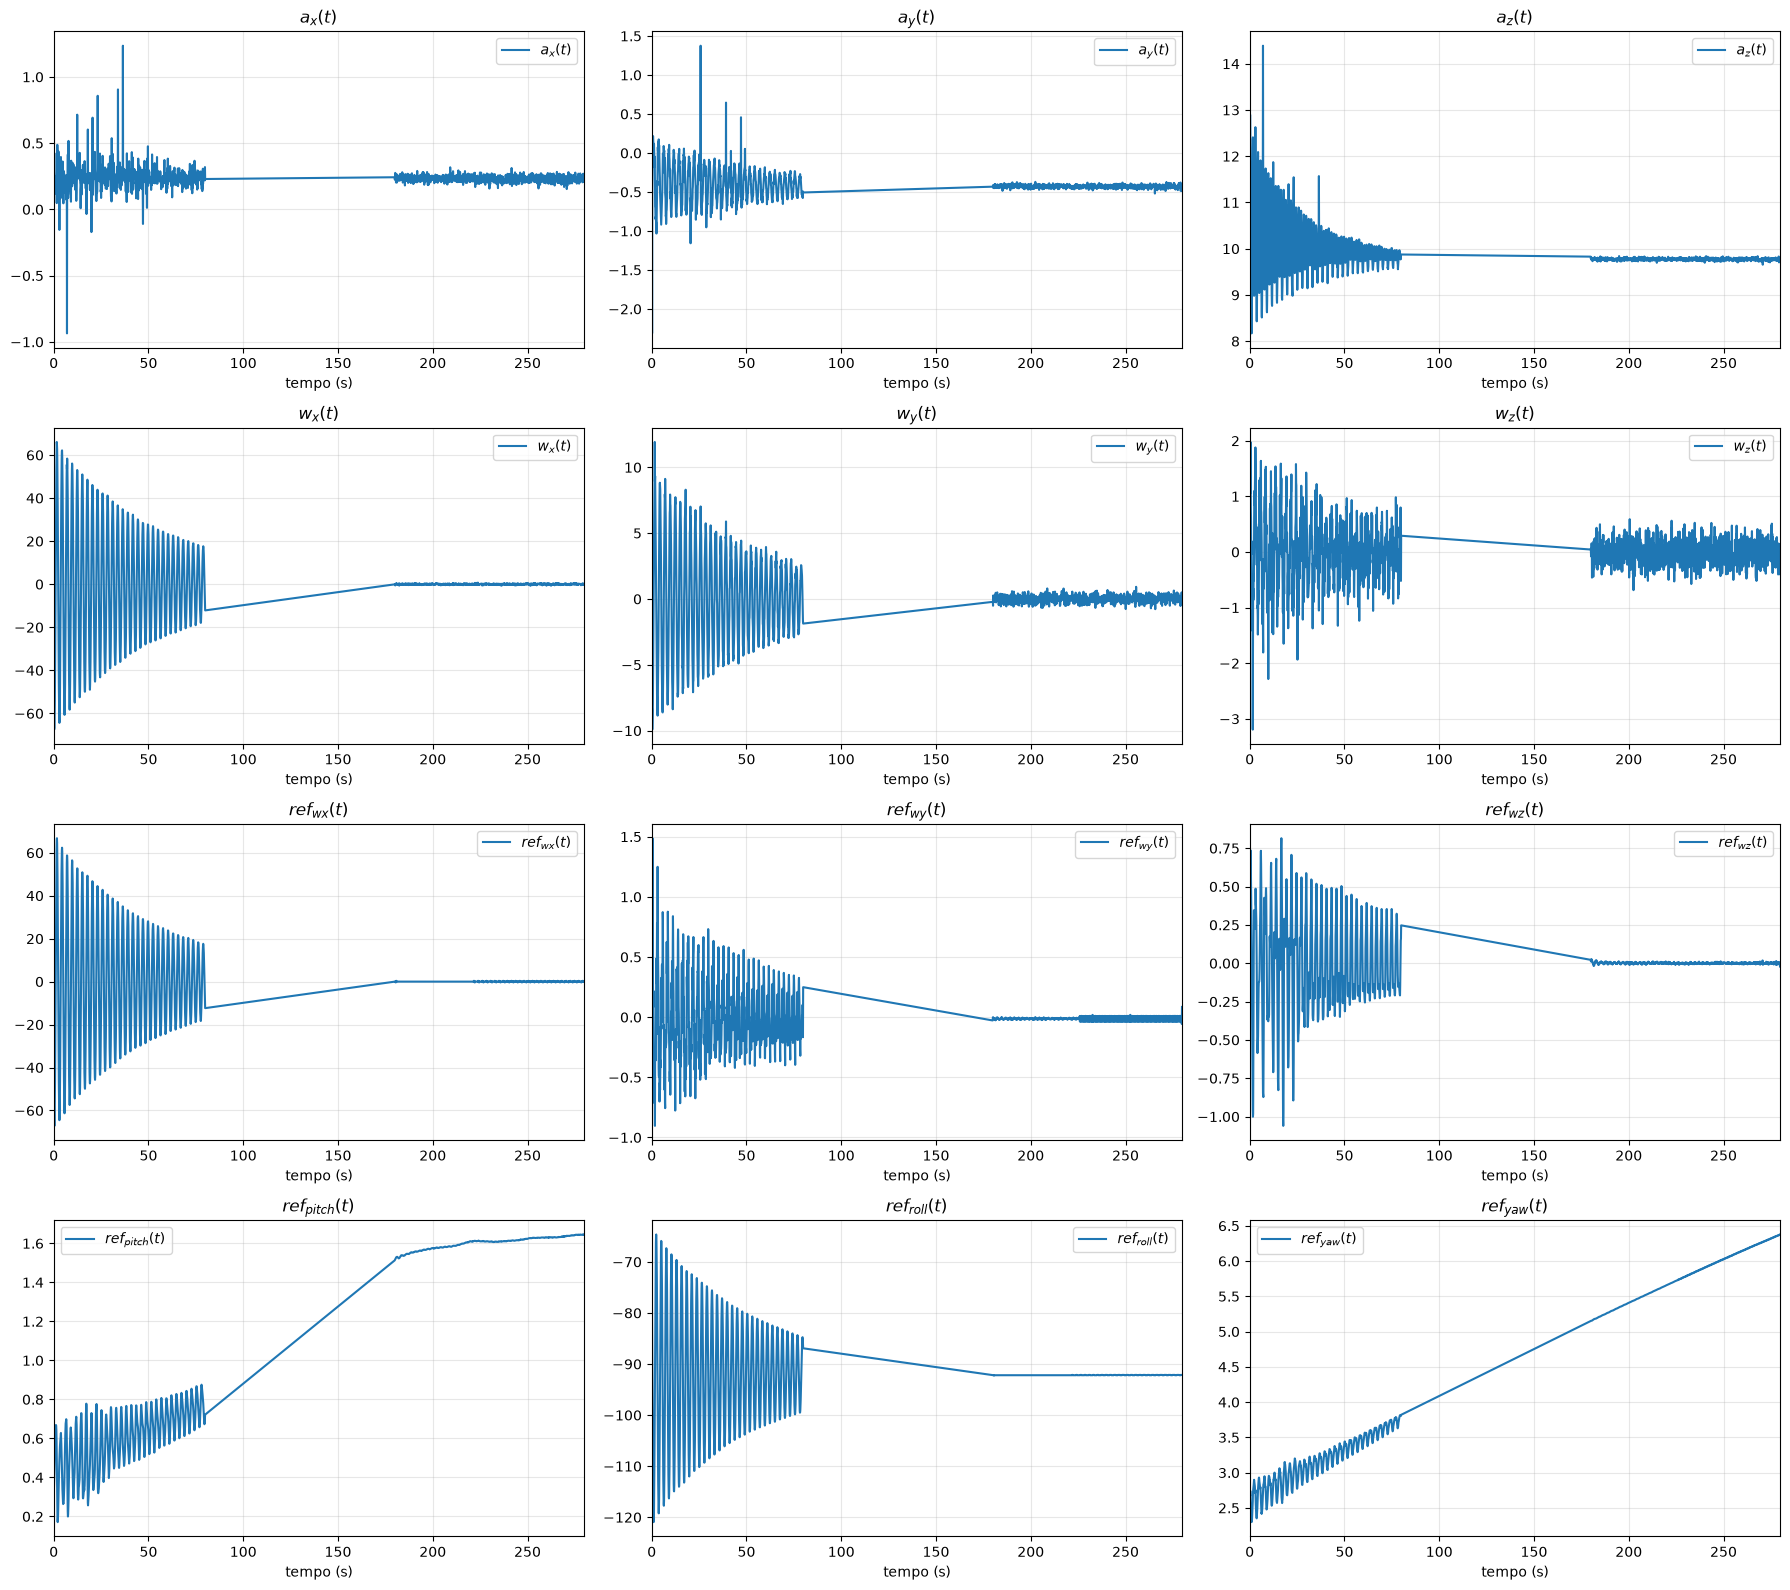

In [8]:
# GRADE DE SUBPLOTS RECORTADA POR FRAÇÃO DO TEMPO TOTAL
def compareAxis(time, data, limits=(0, 1), yLim=None):
    t_min, t_max = time.min(), time.max()
    delta = (t_max - t_min)

    start_time = t_min + (delta * limits[0])
    end_time   = t_min + (delta * limits[1])

    count   = len(data.keys())
    numCols = 3 if count >= 3 else count
    numRows = math.ceil(count / numCols)
    plt.figure(figsize=(6*numCols, 4*numRows))

    for i, (key, values) in enumerate(data.items()):
        mask = (time >= start_time) & (time <= end_time)

        plt.subplot(numRows, numCols, i+1)
        plt.plot(time[mask], values[mask], label=key)

        plt.xlim(start_time, end_time)
        if yLim: plt.ylim(yLim)
        plt.title(key); plt.xlabel('tempo (s)')
        plt.grid(alpha=0.3); plt.legend()

    plt.tight_layout()
    plt.show()


# PAINEL PADRÃO: SENSORES DO MRU NOS EIXOS DO KERNEL, TAXA E ATITUDE DA REFERÊNCIA
def plotAll(df, limits=(0, 1)):
    compareAxis(df.time, {
        '$a_x(t)$': df.ax, '$a_y(t)$': df.ay, '$a_z(t)$': df.az,
        '$w_x(t)$': df.wx, '$w_y(t)$': df.wy, '$w_z(t)$': df.wz,
        '$ref_{wx}(t)$': df.ref_wx, '$ref_{wy}(t)$': df.ref_wy, '$ref_{wz}(t)$': df.ref_wz,
        '$ref_{pitch}(t)$': df.ref_pitch, '$ref_{roll}(t)$': df.ref_roll, '$ref_{yaw}(t)$': df.ref_yaw
    }, limits)


plotAll(df, limits=(0, 1))

# SALVANDO O DATASET
- `dataset.csv` é a entrada de todo o pipeline: o `1 - Filters` lê daqui, e cada etapa seguinte lê a saída da anterior em `results/`

In [9]:
os.makedirs(RESULTS, exist_ok=True)
df.to_csv(f'{RESULTS}/dataset.csv', index=None)
pd.read_csv(f'{RESULTS}/dataset.csv').head()

,time,static,tmp,ax,ay,az,wx,wy,wz,pitch,roll,yaw,ref_pitch,ref_roll,ref_yaw,ref_wx,ref_wy,ref_wz
0,0.0,False,53.0,0.194623,-0.614769,10.733555,-47.92960,-6.92455,1.16726,18.043,1.525,2.936,0.304871,-71.390541,2.771970,-48.363254,-0.461426,0.424375
1,0.1,False,52.9,0.294719,-0.532550,11.618576,-58.13591,-8.13221,1.05996,12.732,0.742,2.725,0.337243,-76.661753,2.723841,-56.744132,1.081554,0.104249
2,0.2,False,53.1,0.256924,-2.312996,12.899422,-67.53252,-8.42212,1.95110,6.586,-0.119,2.578,0.366750,-82.677810,2.667691,-63.259749,-0.383746,0.248578
3,0.3,False,53.3,0.425020,-0.455019,12.406766,-67.39252,-9.92099,1.05936,-0.016,-1.010,2.655,0.387721,-89.209529,2.743322,-66.654402,0.041597,0.372268
4,0.4,False,52.9,0.271203,-0.208931,12.362390,-66.62502,-9.44709,1.97845,-6.779,-1.984,2.656,0.442381,-95.913135,2.624720,-67.172037,1.487548,0.737216
